# Semiconductor fab scheduling

A wafer fab has a dozen lots to finish this week. Each lot follows a route through the tools and
comes back to the same tool group more than once. Lithography tools lose time when the recipe changes,
the furnace runs several lots together, and some lots cannot wait long between steps. The question is
**which tool runs each step, in what order, and which lots share a furnace run**, so that lots finish
by their due dates, with urgent lots first.

In this notebook you will:

1. describe a fab and its lots as Python objects,
2. solve it and draw a machine Gantt chart with lots and batches, then tardiness against due dates,
3. check the result yourself, without trusting the solver's score,
4. change the rules so that the furnace runs full,
5. add lots and see where the fab tips over,
6. restart from an existing schedule, and replan around a tool failure with pinned work.

Requires Python 3.11+: `pip install optimaru matplotlib`

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, Rectangle
from matplotlib.ticker import MaxNLocator

from optimaru import semiconductor_scheduling as fab
from optimaru.semiconductor_scheduling import constraints as rules
from optimaru.semiconductor_scheduling.models import (
    LotModel, MachineModel, MachineOptionModel, OperationModel, SemiconductorScheduleModel, SetupTimeModel,
    TimeWindowModel, TransportTimeModel,
)

COLORS = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100", "#e87ba4", "#008300", "#6250d6", "#e34948"]
INK, MUTED = "#52514e", "#898781"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.edgecolor": "#c3c2b7", "axes.labelcolor": INK, "axes.titlesize": 12,
    "axes.titleweight": "bold", "axes.titlelocation": "left", "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "xtick.color": MUTED, "ytick.color": MUTED,
    "grid.color": "#e1e0d9", "grid.linewidth": 0.8, "legend.frameon": False, "font.size": 10,
})

## 1. Describe the fab

Times are integers. This notebook reads them as hours from the start of the week.

| Object | What it holds |
| --- | --- |
| `MachineModel` | one tool: its group, how many lots it runs at once, its downtime windows |
| `LotModel` | one lot: product, release time, due time, priority, and its route of operations |
| `OperationModel` | one route step: recipe family, eligible tools, minimum and maximum wait afterwards |
| `MachineOptionModel` | one eligible tool for a step, with its duration and a preference cost |
| `SetupTimeModel` | time to change a tool group from one recipe family to another |
| `TransportTimeModel` | time to move a lot between two tool groups |

The model also has reticles and operators as `auxiliary_resources`, and a `max_cycle_time` per lot. This
notebook leaves them out to keep the chart readable.

The fab below is fictional. Alpha and Beta visit lithography twice and Gamma once, the second lithography tool is one
hour slower and has a preference cost, and a lot must reach its next step within 12 hours of cleaning.
Every fifth lot is urgent, with priority 3. The furnace holds three lots of the same oxide recipe.

In [2]:
ROUTES = {
    "Alpha": ["CLEAN", "LITHO", "ETCH", "FURNACE", "LITHO", "ETCH"],
    "Beta": ["CLEAN", "LITHO", "FURNACE", "LITHO", "ETCH"],
    "Gamma": ["CLEAN", "LITHO", "ETCH", "FURNACE"],
}
TOOLS = {"CLEAN": ["CL1"], "LITHO": ["LI1", "LI2"], "ETCH": ["ET1", "ET2"], "FURNACE": ["FU1"]}
HOURS = {"CLEAN": 3, "LITHO": 6, "ETCH": 5, "FURNACE": 14}
FURNACE_SIZE, QUEUE_LIMIT, SETUP_LITHO, SETUP_FURNACE = 3, 12, 3, 4
PRODUCTS = list(ROUTES)


def recipe(step, product, lot_number):
    if step == "LITHO":
        return f"Litho {product}"
    return f"Oxide {1 + lot_number % 2}" if step == "FURNACE" else step


def make_operation(position, step, product, lot_number):
    options = [
        MachineOptionModel(machine_id=tool, duration=HOURS[step] + (k if step == "LITHO" else 0),
                           preference_cost=2 * k)
        for k, tool in enumerate(TOOLS[step])
    ]
    return OperationModel(id=f"{position + 1}-{step}", family=recipe(step, product, lot_number),
                          eligible_machines=options, max_queue_time=QUEUE_LIMIT if step == "CLEAN" else None)


def make_fab(lot_count=12):
    """A fresh, unsolved fab. solve works in place, so each experiment gets its own."""
    rng = np.random.default_rng(8)
    lots = []
    for i in range(lot_count):
        product = PRODUCTS[i % len(PRODUCTS)]
        route = ROUTES[product]
        release = int(rng.integers(0, 30))
        due = release + int(sum(HOURS[step] for step in route) * 1.5) + int(rng.integers(0, 12))
        lots.append(LotModel(
            id=f"L{i + 1:02d}", product=product, release_time=release, due_time=due,
            priority=3 if i % 5 == 0 else 1,
            operations=[make_operation(k, step, product, i) for k, step in enumerate(route)],
        ))
    setups = [SetupTimeModel(machine_group="LITHO", from_family=f"Litho {a}", to_family=f"Litho {b}",
                             duration=SETUP_LITHO) for a in PRODUCTS for b in PRODUCTS if a != b]
    setups += [SetupTimeModel(machine_group="FURNACE", from_family=f"Oxide {a}", to_family=f"Oxide {b}",
                              duration=SETUP_FURNACE) for a, b in ((1, 2), (2, 1))]
    moves = [TransportTimeModel(from_group=a, to_group=b, duration=1) for a in TOOLS for b in TOOLS if a != b]
    machines = [
        MachineModel(id="CL1", group="CLEAN"),
        MachineModel(id="LI1", group="LITHO"),
        MachineModel(id="LI2", group="LITHO"),
        MachineModel(id="ET1", group="ETCH", unavailable=[TimeWindowModel(start=40, end=52)]),
        MachineModel(id="ET2", group="ETCH"),
        MachineModel(id="FU1", group="FURNACE", batch_capacity=FURNACE_SIZE, minimum_batch_size=2),
    ]
    return SemiconductorScheduleModel(machines=machines, setup_times=setups, transport_times=moves, lots=lots)


problem = make_fab()
steps = sum(len(lot.operations) for lot in problem.lots)
print(f"{len(problem.lots)} lots, {steps} operations, {len(problem.machines)} tools")

12 lots, 60 operations, 6 tools


Each row below is a product's route. The same tool group appears twice in most rows, which is what
makes a fab re-entrant: a lot returning to lithography competes with lots seeing it for the first time.

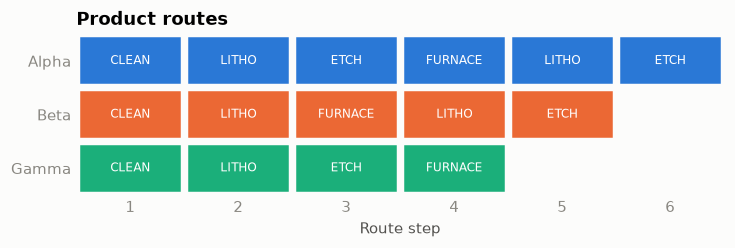

In [3]:
fig, ax = plt.subplots(figsize=(7.6, 1.9))
for row, (product, route) in enumerate(ROUTES.items()):
    for column, step in enumerate(route):
        ax.add_patch(Rectangle((column + 0.04, row + 0.08), 0.92, 0.84, color=COLORS[PRODUCTS.index(product)]))
        ax.text(column + 0.5, row + 0.5, step, ha="center", va="center", color="white", fontsize=8)
ax.set(xlim=(0, 6), ylim=(len(ROUTES), 0), xlabel="Route step")
ax.set_xticks(np.arange(6) + 0.5, range(1, 7))
ax.set_yticks(np.arange(len(ROUTES)) + 0.5, list(ROUTES))
ax.tick_params(length=0)
ax.spines[["left", "bottom"]].set_visible(False)
ax.set_title("Product routes")
plt.show()

## 2. Solve it

`fab.solve` works in place: it fills `assignments` on the model and returns `(hard, soft)`. Each
assignment holds a tool, a start and an end, and lots in the same furnace run share a `batch_id`.

This use case runs simulated annealing in Python. Unlike a time limit, `max_iterations` stops it at the
same point on every run, so the helper below uses that and a generous clock.

The score has two levels, compared in order:

- **hard**: the sum of the rule breaks, where `0` means the schedule can be run. It covers tool overlaps,
  route order, release times, batch size and recipe, setup time, downtime, queue limits and transport.
- **soft**: minus a weighted sum of what the schedule costs: `10 x` the priority-weighted tardiness, plus
  the total cycle time, the makespan, tool preference costs, missing lots in small batches, and the load
  difference between tools in a group.

In [4]:
def run(schedule, iterations, seed, constraints=None):
    config = fab.SolverConfig(max_iterations=iterations, spent_limit_seconds=60, random_seed=seed)
    return fab.solve(schedule, config=config, constraints=constraints)


plan = make_fab()
print("score            :", run(plan, 6000, 42))
print("makespan         :", plan.makespan)
print("weighted tardiness:", plan.total_weighted_tardiness)
print("total cycle time :", plan.total_cycle_time)

score            : (0, -3031.0)
makespan         : 108
weighted tardiness: 207
total cycle time : 815


### The schedule

Each row is a tool, and the furnace has one lane per lot it can hold. Bars carry the lot number and
use one color per product. A black frame marks one furnace run, light gray bars are recipe setups, and
dark gray bars are planned downtime.

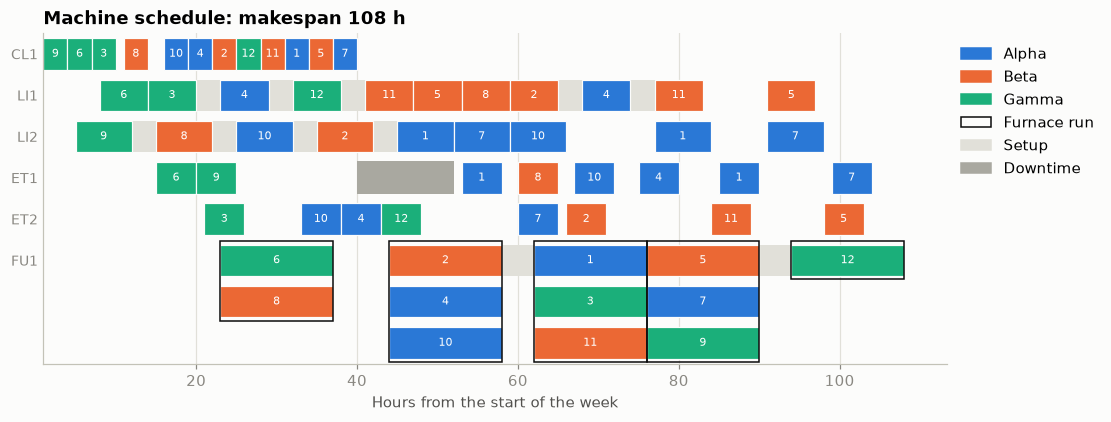

In [5]:
def key_of(assignment):
    return assignment.lot_id, assignment.operation_id


def family_of(schedule):
    return {(lot.id, operation.id): operation.family for lot in schedule.lots for operation in lot.operations}


def setups_needed(schedule):
    """(tool, start, duration) of each recipe change, walking each tool the way the score does."""
    table = {(s.machine_group, s.from_family, s.to_family): s.duration for s in schedule.setup_times}
    families = family_of(schedule)
    found = []
    for machine in schedule.machines:
        rows = sorted((a for a in schedule.assignments if a.machine_id == machine.id),
                      key=lambda a: (a.start, a.end))
        for before, after in zip(rows, rows[1:]):
            needed = table.get((machine.group, families[key_of(before)], families[key_of(after)]), 0)
            if needed and before.end <= after.start:
                found.append((machine.id, after.start - needed, needed))
    return found


def draw_fab(ax, schedule, outlined=()):
    product_of = {lot.id: lot.product for lot in schedule.lots}
    rows, labels, row = {}, [], 0
    for machine in schedule.machines:
        rows[machine.id] = row
        labels += [machine.id] + [""] * (machine.batch_capacity - 1)
        row += machine.batch_capacity
    lanes = {}
    for machine in schedule.machines:
        for window in machine.unavailable:
            ax.barh(rows[machine.id] + (machine.batch_capacity - 1) / 2, window.end - window.start,
                    left=window.start, height=machine.batch_capacity - 0.2, color="#a9a8a0", zorder=1)
    for tool, start, duration in setups_needed(schedule):
        ax.barh(rows[tool], duration, left=start, height=0.76, color="#e1e0d9", zorder=1)
    for a in sorted(schedule.assignments, key=lambda item: (item.start, item.lot_id)):
        lane = lanes.get((a.machine_id, a.start), 0)
        lanes[(a.machine_id, a.start)] = lane + 1
        moved = key_of(a) in outlined
        ax.barh(rows[a.machine_id] + lane, a.end - a.start, left=a.start, height=0.76,
                zorder=5 if moved else 2, linewidth=1.8 if moved else 0.8,
                color=COLORS[PRODUCTS.index(product_of[a.lot_id])], edgecolor=COLORS[6] if moved else "#fcfcfb")
        ax.text((a.start + a.end) / 2, rows[a.machine_id] + lane, str(int(a.lot_id[1:])), ha="center",
                va="center", color="white", fontsize=7, zorder=6)
    for batch in {a.batch_id for a in schedule.assignments if a.batch_id}:
        members = [a for a in schedule.assignments if a.batch_id == batch]
        first = members[0]
        ax.add_patch(Rectangle((first.start, rows[first.machine_id] - 0.46), first.end - first.start,
                               len(members) - 0.08, fill=False, edgecolor="#0b0b0b", linewidth=1, zorder=4))
    ax.set_yticks(range(len(labels)), labels, fontsize=9)
    ax.set_ylim(len(labels) - 0.5, -0.5)
    ax.tick_params(axis="y", length=0)
    ax.grid(True, axis="x")
    return [Patch(color=COLORS[k], label=p) for k, p in enumerate(PRODUCTS)] + [
        Patch(facecolor="none", edgecolor="#0b0b0b", label="Furnace run"),
        Patch(color="#e1e0d9", label="Setup"), Patch(color="#a9a8a0", label="Downtime"),
    ]


fig, ax = plt.subplots(figsize=(10.6, 3.9))
handles = draw_fab(ax, plan)
ax.set(xlabel="Hours from the start of the week")
ax.set_title(f"Machine schedule: makespan {plan.makespan} h")
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

### Tardiness against due dates

The schedule is only useful if lots leave on time. Each row below is a lot, sorted by due time, from
its release to its completion. The tick is the due time, and the red part is how late the lot is.

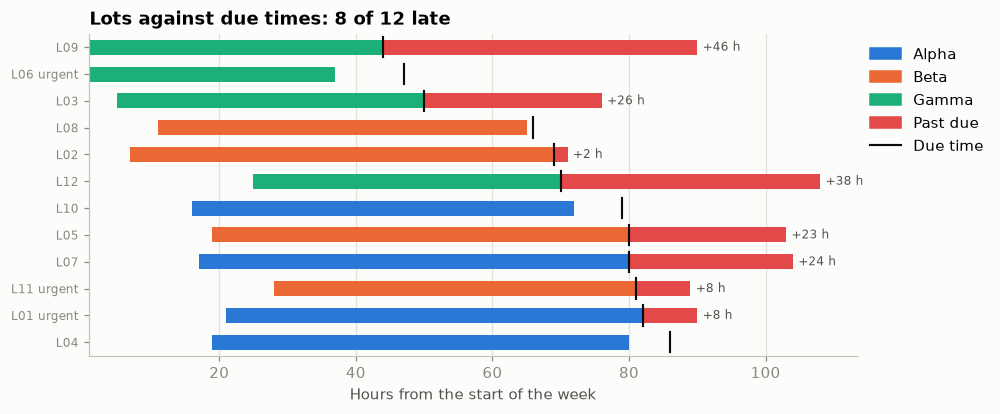

In [6]:
def completion(schedule):
    last = {(lot.id, lot.operations[-1].id): lot.id for lot in schedule.lots}
    return {last[key_of(a)]: a.end for a in schedule.assignments if key_of(a) in last}


def draw_lots(ax, schedule):
    finished = completion(schedule)
    ordered = sorted(schedule.lots, key=lambda lot: lot.due_time)
    for row, lot in enumerate(ordered):
        color = COLORS[PRODUCTS.index(lot.product)]
        on_time_end = min(finished[lot.id], lot.due_time)
        ax.barh(row, on_time_end - lot.release_time, left=lot.release_time, height=0.56, color=color)
        if finished[lot.id] > lot.due_time:
            ax.barh(row, finished[lot.id] - lot.due_time, left=lot.due_time, height=0.56, color=COLORS[7])
            late = finished[lot.id] - lot.due_time
            ax.text(finished[lot.id] + 0.8, row, f"+{late} h", va="center", color=INK, fontsize=8)
        ax.plot([lot.due_time] * 2, [row - 0.38, row + 0.38], color="#0b0b0b", linewidth=1.4, zorder=3)
    ax.set_yticks(range(len(ordered)),
                  [f"{lot.id} urgent" if lot.priority > 1 else lot.id for lot in ordered], fontsize=8)
    ax.set_ylim(len(ordered) - 0.5, -0.5)
    ax.grid(True, axis="x")
    ax.set_xlabel("Hours from the start of the week")


late_lots = sum(completion(plan)[lot.id] > lot.due_time for lot in plan.lots)
fig, ax = plt.subplots(figsize=(9, 3.8))
draw_lots(ax, plan)
ax.set_title(f"Lots against due times: {late_lots} of {len(plan.lots)} late")
ax.legend(handles=[*(Patch(color=COLORS[k], label=p) for k, p in enumerate(PRODUCTS)),
                   Patch(color=COLORS[7], label="Past due"),
                   Line2D([], [], color="#0b0b0b", linewidth=1.4, label="Due time")],
          loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## 3. Check the result yourself

The assignments are plain data, so the hard rules can be recomputed from them with no solver code. This
walks each tool and each lot, then rebuilds the tardiness and makespan.

In [7]:
def lots_per_run(schedule):
    runs = Counter(a.batch_id for a in schedule.assignments if a.batch_id)
    return sorted(runs.values())


def audit(schedule):
    by_key = {key_of(a): a for a in schedule.assignments}
    families = family_of(schedule)
    machines = {m.id: m for m in schedule.machines}
    moves = {(t.from_group, t.to_group): t.duration for t in schedule.transport_times}
    setups = {(s.machine_group, s.from_family, s.to_family): s.duration for s in schedule.setup_times}
    breaks = dict.fromkeys(("tool overlap", "furnace over capacity", "mixed recipe in a run", "setup time",
                            "route order", "before release", "queue limit", "transport time", "downtime"), 0)
    for machine in schedule.machines:
        rows = sorted((a for a in schedule.assignments if a.machine_id == machine.id), key=lambda a: a.start)
        for a in rows:
            for window in machine.unavailable:
                breaks["downtime"] += max(0, min(a.end, window.end) - max(a.start, window.start))
            together = [b for b in rows if b.start < a.end and a.start < b.end]
            if machine.batch_capacity == 1:
                breaks["tool overlap"] += len(together) > 1
            else:
                breaks["furnace over capacity"] += len(together) > machine.batch_capacity
                breaks["mixed recipe in a run"] += len({families[key_of(b)] for b in together}) > 1
        for before, after in zip(rows, rows[1:]):
            needed = setups.get((machine.group, families[key_of(before)], families[key_of(after)]), 0)
            same_run = machine.batch_capacity > 1 and families[key_of(before)] == families[key_of(after)]
            breaks["setup time"] += bool(needed) and not same_run and before.end + needed > after.start
    for lot in schedule.lots:
        route = [by_key[(lot.id, operation.id)] for operation in lot.operations]
        breaks["before release"] += route[0].start < lot.release_time
        for operation, before, after in zip(lot.operations, route, route[1:]):
            wait = after.start - before.end
            breaks["route order"] += wait < 0
            group = machines[before.machine_id].group, machines[after.machine_id].group
            breaks["transport time"] += wait < moves.get(group, 0)
            breaks["queue limit"] += operation.max_queue_time is not None and wait > operation.max_queue_time
    return breaks


finished = completion(plan)
tardiness = sum(max(0, finished[lot.id] - lot.due_time) * lot.priority for lot in plan.lots)
for rule, count in audit(plan).items():
    print(f"{rule:22}: {count}")
print(f"weighted tardiness    : {tardiness}, solver says {plan.total_weighted_tardiness}")
print(f"makespan              : {max(finished.values())}, solver says {plan.makespan}")
print(f"lots per furnace run  : {lots_per_run(plan)}")

tool overlap          : 0
furnace over capacity : 0
mixed recipe in a run : 0
setup time            : 0
route order           : 0
before release        : 0
queue limit           : 0
transport time        : 0
downtime              : 0
weighted tardiness    : 207, solver says 207
makespan              : 108, solver says 108
lots per furnace run  : [1, 2, 3, 3, 3]


## 4. Change the rules, not the solver

Every rule is a plugin. `list_constraints()` shows what ships with this use case, and `constraints=`
replaces the set, so only listed rules are scored. This use case has no `get_constraints` helper:
`rules.DEFAULTS` is the default list, and the small function below swaps one rule in it.

In [8]:
for name in fab.list_constraints():
    print(name)


def with_rule(changed):
    return [changed if rule.name == changed.name else rule for rule in rules.DEFAULTS]

machine_eligibility
lot_route_precedence
machine_capacity
batch_capacity
batch_family_compatibility
setup_transitions
maintenance_windows
maximum_queue_time
minimum_queue_time
inter_tool_transport
auxiliary_resource_capacity
auxiliary_resource_availability
pinned_assignments
maximum_cycle_time
machine_preference
minimum_batch_fill
machine_load_balance
weighted_tardiness
total_cycle_time
makespan


`weight` scales a rule, `hard` moves it between levels, and `exponent=2` makes large violations much
costlier than small ones.

The furnace is the longest step, and a part-empty run wastes it. `MinimumBatchFill` charges for each lot
missing below a tool's `minimum_batch_size`, which is 2 here, so it targets runs with a single lot. By
default it costs almost nothing. `weight=2000` makes one missing lot cost as much as 200 hours of
weighted tardiness.

Runs differ a lot from seed to seed on this problem, so one before-and-after pair could be luck. This
compares both rule sets on six consecutive seeds, with one dot per seed and a tick at the median. A
hollow dot is a schedule that still has hard breaks, so it could not be run as it stands.

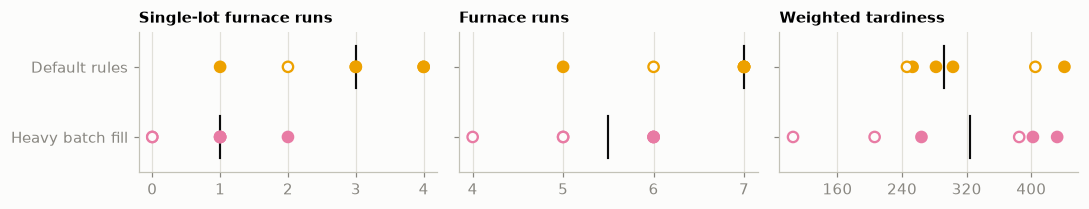

Default rules: 4 of 6 seeds feasible
  seed 1: hard  -5, lots per run [1, 1, 1, 2, 2, 2, 3], tardiness 405, makespan 131
  seed 2: hard   0, lots per run [1, 2, 3, 3, 3], tardiness 253, makespan 118
  seed 3: hard   0, lots per run [1, 1, 1, 2, 2, 2, 3], tardiness 441, makespan 130
  seed 4: hard   0, lots per run [1, 1, 1, 1, 2, 3, 3], tardiness 303, makespan 137
  seed 5: hard  -1, lots per run [1, 1, 2, 2, 3, 3], tardiness 246, makespan 130
  seed 6: hard   0, lots per run [1, 1, 1, 1, 2, 3, 3], tardiness 282, makespan 136
Heavy batch fill: 3 of 6 seeds feasible
  seed 1: hard  -4, lots per run [1, 2, 3, 3, 3], tardiness 385, makespan 124
  seed 2: hard  -3, lots per run [3, 3, 3, 3], tardiness 105, makespan 101
  seed 3: hard   0, lots per run [1, 1, 2, 2, 3, 3], tardiness 402, makespan 143
  seed 4: hard   0, lots per run [1, 2, 2, 2, 2, 3], tardiness 432, makespan 127
  seed 5: hard   0, lots per run [1, 2, 2, 2, 2, 3], tardiness 264, makespan 119
  seed 6: hard  -3, lots per run

In [9]:
ITERATIONS, TEST_SEEDS = 3000, range(1, 7)
fill_rule = with_rule(rules.MinimumBatchFill(weight=2000))
compared = {}
for label, constraints in (("Default rules", None), ("Heavy batch fill", fill_rule)):
    compared[label] = []
    for seed in TEST_SEEDS:
        schedule = make_fab()
        run(schedule, ITERATIONS, seed, constraints)
        compared[label].append(schedule)

measures = {
    "Single-lot furnace runs": lambda s: lots_per_run(s).count(1),
    "Furnace runs": lambda s: len(lots_per_run(s)),
    "Weighted tardiness": lambda s: s.total_weighted_tardiness,
}
fig, axes = plt.subplots(1, 3, figsize=(10, 2), sharey=True)
for ax, (title, measure) in zip(axes, measures.items()):
    for row, (label, schedules) in enumerate(compared.items()):
        values = [measure(s) for s in schedules]
        color = COLORS[3 + row]
        ax.scatter(values, [row] * len(values), s=46, linewidth=1.5, edgecolor=color, zorder=3,
                   facecolor=[color if s.score_hard == 0 else "#fcfcfb" for s in schedules])
        ax.plot([np.median(values)] * 2, [row - 0.3, row + 0.3], color="#0b0b0b", linewidth=1.4, zorder=2)
    ax.set_title(title, fontsize=10)
    ax.grid(True, axis="x")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=5))
axes[0].set_yticks(range(len(compared)), list(compared))
axes[0].set_ylim(len(compared) - 0.5, -0.5)
plt.tight_layout()
plt.show()

for label, schedules in compared.items():
    feasible = sum(s.score_hard == 0 for s in schedules)
    print(f"{label}: {feasible} of {len(schedules)} seeds feasible")
    for seed, schedule in zip(TEST_SEEDS, schedules):
        print(f"  seed {seed}: hard {schedule.score_hard:3}, lots per run {lots_per_run(schedule)}, "
              f"tardiness {schedule.total_weighted_tardiness}, makespan {schedule.makespan}")

Read the first panel for what the rule asks for and the others for what it costs. A rule that wins on
its own measure can still lose elsewhere, and six seeds is a small sample. Weighted tardiness on a
schedule with hard breaks is not an achievement, which is why those dots are hollow. Scores with
different weights cannot be compared directly, so the chart uses each schedule's own measures.

## 5. How many lots can the fab take?

Release more lots into the same tools and the queues grow. This keeps the first lots and due dates as
they are and adds more, with one solve per lot count. Tardiness is shown per lot, because the total
would rise anyway with more lots.

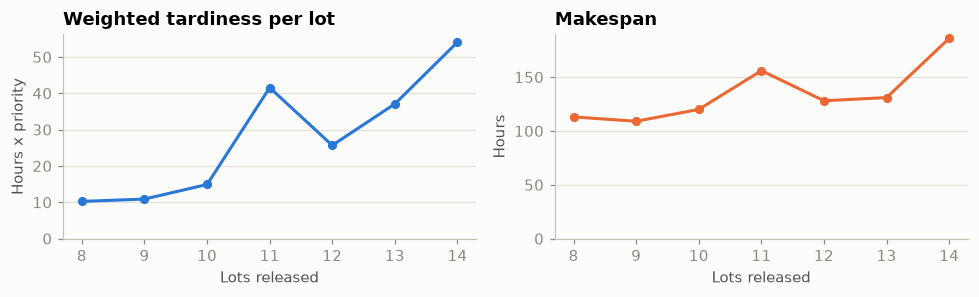

8 lots: hard   0, tardiness   82, makespan 113
9 lots: hard   0, tardiness   98, makespan 109
10 lots: hard   0, tardiness  149, makespan 120
11 lots: hard   0, tardiness  457, makespan 156
12 lots: hard   0, tardiness  308, makespan 128
13 lots: hard   0, tardiness  482, makespan 131
14 lots: hard   0, tardiness  757, makespan 186


In [10]:
lot_counts = [8, 9, 10, 11, 12, 13, 14]
loaded = []
for count in lot_counts:
    schedule = make_fab(count)
    run(schedule, 2000, 42)
    loaded.append(schedule)

fig, axes = plt.subplots(1, 2, figsize=(9, 2.8), sharex=True)
axes[0].plot(lot_counts, [s.total_weighted_tardiness / len(s.lots) for s in loaded], color=COLORS[0],
             linewidth=2, marker="o", markersize=5)
axes[0].set(title="Weighted tardiness per lot", xlabel="Lots released", ylabel="Hours x priority",
            ylim=(0, None))
axes[1].plot(lot_counts, [s.makespan for s in loaded], color=COLORS[1], linewidth=2, marker="o", markersize=5)
axes[1].set(title="Makespan", xlabel="Lots released", ylabel="Hours", ylim=(0, None))
for ax in axes:
    ax.set_xticks(lot_counts)
    ax.grid(True, axis="y")
plt.tight_layout()
plt.show()

for count, schedule in zip(lot_counts, loaded):
    print(f"{count} lots: hard {schedule.score_hard:3}, tardiness {schedule.total_weighted_tardiness:4}, "
          f"makespan {schedule.makespan}")

Each point is one solve with the same iteration budget, and more lots make each iteration slower and the
search harder, so read the shape, not a single step.

## 6. Restart from an existing schedule

`with_initial_solution(problem, solution)` returns a copy of `problem` whose search starts from
`solution`. A complete solution is scored as supplied, so `solve` returns it unchanged unless the search
finds something strictly better, and the score cannot get worse.

Internally the search works on a tool choice and a priority per operation, which a decoder turns into a
schedule. Decoding can give a different schedule from the one supplied, so the search is not guaranteed
to stay close to it.

**Give each restart its own `random_seed`.** A solve returns the best schedule it saw, and the same start
with the same seed repeats the same search, so once a round finds nothing, every later round returns the
same schedule. Hollow points below still have hard breaks.

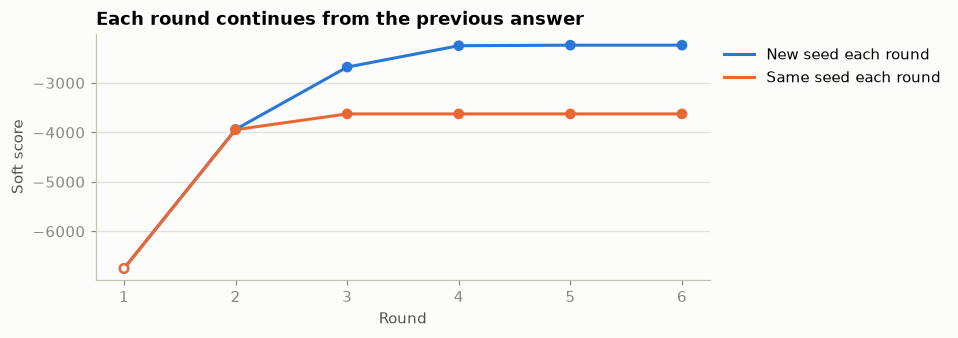

same seed: 3 of 5 restarts returned their start, final (0, -3627.0)
new seed : 1 of 5 restarts returned their start, final (0, -2237.0)


In [11]:
ROUNDS, ROUND_ITERATIONS, FIRST_SEED = 6, 1000, 3


def schedule_of(solution):
    return sorted((a.lot_id, a.operation_id, a.machine_id, a.start) for a in solution.assignments)


def run_rounds(seed_of_round):
    solution = make_fab()
    run(solution, ROUND_ITERATIONS, FIRST_SEED)
    history, repeats = [(solution.score_hard, solution.score_soft)], 0
    for round_number in range(1, ROUNDS):
        previous = schedule_of(solution)
        restart = fab.with_initial_solution(make_fab(), solution)
        run(restart, ROUND_ITERATIONS, seed_of_round(round_number))
        solution = restart
        history.append((solution.score_hard, solution.score_soft))
        repeats += schedule_of(solution) == previous
    return history, repeats


same_seed, same_repeats = run_rounds(lambda round_number: FIRST_SEED)
new_seed, new_repeats = run_rounds(lambda round_number: FIRST_SEED + 10 * round_number)

fig, ax = plt.subplots(figsize=(7.2, 2.9))
turns = np.arange(1, ROUNDS + 1)
for history, color, label in ((new_seed, COLORS[0], "New seed each round"),
                              (same_seed, COLORS[1], "Same seed each round")):
    soft = [s for _, s in history]
    ax.plot(turns, soft, color=color, linewidth=2, label=label)
    ax.scatter(turns, soft, s=30, zorder=3, edgecolor=color, linewidth=1.5,
               facecolor=["#fcfcfb" if hard < 0 else color for hard, _ in history])
ax.set(title="Each round continues from the previous answer", xlabel="Round", ylabel="Soft score")
ax.grid(True, axis="y")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

print(f"same seed: {same_repeats} of {ROUNDS - 1} restarts returned their start, final {same_seed[-1]}")
print(f"new seed : {new_repeats} of {ROUNDS - 1} restarts returned their start, final {new_seed[-1]}")

A new seed does not guarantee progress either. A flat stretch means the search has stalled, which is
not a proof that the schedule is optimal.

### Replan around a tool failure

At hour 45 etcher `ET2` fails, and it will be down for 40 hours. Work that has started cannot change, so
those operations go in `pinned_assignments`: the decoder keeps them exactly as they are, and a
`pinned_assignments` hard rule scores any change. A step already running on `ET2` finishes first, so the
downtime starts when it ends.

Pinning alone does not stop the schedule moving other work into the past, because nothing says what
time it is. So each lot that has started gets a `min_queue_time` after its last started step, which holds
the next step until now, and lots that have not started get a later `release_time`.

This compares three replans:

- **Pinned, old schedule**: the search starts from the old schedule with started work pinned.
- **Pinned, no schedule**: the same pins, with everything else built again.
- **No pins, old schedule**: nothing is held, to show what pins protect.

32 of 60 operations have started, ET2 is down from hour 48
Pinned, old schedule  : hard   0, tardiness  224, makespan 108, 9 moved, 0 started operations moved, 0 open operations in the past
Pinned, no schedule   : hard   0, tardiness  251, makespan 139, 10 moved, 0 started operations moved, 0 open operations in the past
No pins, old schedule : hard   0, tardiness  219, makespan 107, 27 moved, 9 started operations moved, 0 open operations in the past


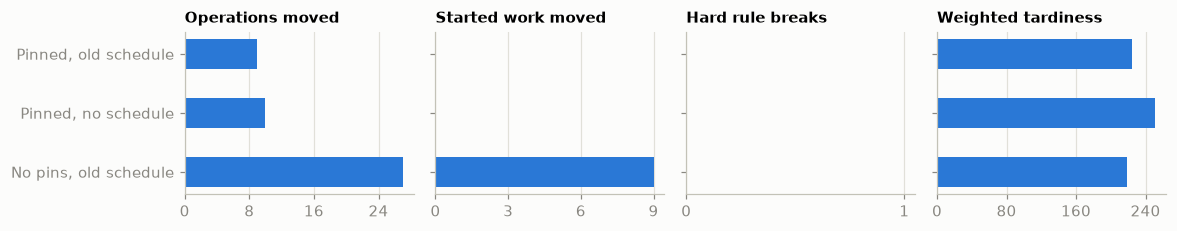

In [12]:
NOW, DOWN_TOOL, DOWN_HOURS, REPLAN_ITERATIONS, REPLAN_SEED = 45, "ET2", 40, 3000, 43
started = [a for a in plan.assignments if a.start < NOW]
started_keys = {key_of(a) for a in started}
down_from = max([NOW, *(a.end for a in started if a.machine_id == DOWN_TOOL)])
old_place = {key_of(a): (a.machine_id, a.start) for a in plan.assignments}


def replanning_fab(pin):
    schedule = make_fab()
    tool = next(m for m in schedule.machines if m.id == DOWN_TOOL)
    tool.unavailable.append(TimeWindowModel(start=down_from, end=down_from + DOWN_HOURS))
    if not pin:
        return schedule
    schedule.pinned_assignments = [a.model_copy() for a in started]
    ends = {key_of(a): a.end for a in started}
    for lot in schedule.lots:
        done = [operation for operation in lot.operations if (lot.id, operation.id) in started_keys]
        if done:
            done[-1].min_queue_time = max(done[-1].min_queue_time, NOW - ends[(lot.id, done[-1].id)])
        else:
            lot.release_time = max(lot.release_time, NOW)
    return schedule


replans = {
    "Pinned, old schedule": fab.with_initial_solution(replanning_fab(True), plan),
    "Pinned, no schedule": replanning_fab(True),
    "No pins, old schedule": fab.with_initial_solution(replanning_fab(False), plan),
}
for schedule in replans.values():
    run(schedule, REPLAN_ITERATIONS, REPLAN_SEED)


def moved_operations(schedule):
    return [key_of(a) for a in schedule.assignments if (a.machine_id, a.start) != old_place[key_of(a)]]


def started_moved(schedule):
    return sum(key in started_keys for key in moved_operations(schedule))


print(f"{len(started)} of {len(plan.assignments)} operations have started, "
      f"{DOWN_TOOL} is down from hour {down_from}")
for name, schedule in replans.items():
    in_past = sum(a.start < NOW for a in schedule.assignments if key_of(a) not in started_keys)
    print(f"{name:22}: hard {schedule.score_hard:3}, tardiness {schedule.total_weighted_tardiness:4}, "
          f"makespan {schedule.makespan}, {len(moved_operations(schedule))} moved, "
          f"{started_moved(schedule)} started operations moved, {in_past} open operations in the past")

names = list(replans)
y = np.arange(len(names))
panels = [("Operations moved", [len(moved_operations(s)) for s in replans.values()]),
          ("Started work moved", [started_moved(s) for s in replans.values()]),
          ("Hard rule breaks", [-s.score_hard for s in replans.values()]),
          ("Weighted tardiness", [s.total_weighted_tardiness for s in replans.values()])]
fig, axes = plt.subplots(1, 4, figsize=(10.8, 2.2), sharey=True)
for ax, (title, values) in zip(axes, panels):
    ax.barh(y, values, height=0.5, color=COLORS[0])
    ax.set_title(title, fontsize=10)
    ax.set_xlim(0, max(*values, 1) * 1.05)
    ax.grid(True, axis="x")
    ax.xaxis.set_major_locator(MaxNLocator(integer=True, nbins=4))
axes[0].set_yticks(y, names)
axes[0].invert_yaxis()
plt.tight_layout()
plt.show()

Below is the first replan, with moved operations outlined in purple. Everything that started before the
red line has not changed.

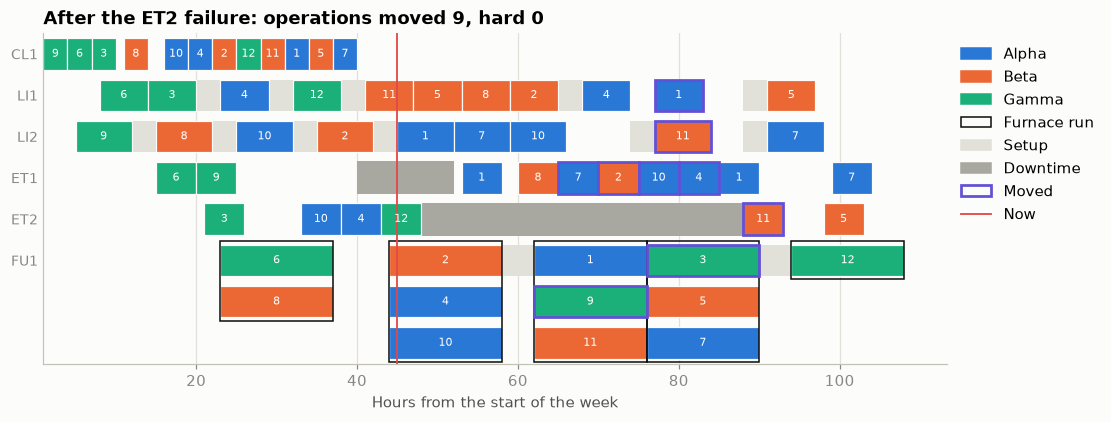

In [13]:
shown = replans["Pinned, old schedule"]
fig, ax = plt.subplots(figsize=(10.6, 3.9))
handles = draw_fab(ax, shown, outlined=set(moved_operations(shown)))
ax.axvline(NOW, color=COLORS[7], linewidth=1.2, zorder=5)
ax.set(xlabel="Hours from the start of the week")
ax.set_title(f"After the {DOWN_TOOL} failure: operations moved {len(moved_operations(shown))}, "
             f"hard {shown.score_hard}")
handles += [Patch(facecolor="none", edgecolor=COLORS[6], linewidth=1.8, label="Moved"),
            Line2D([], [], color=COLORS[7], linewidth=1.2, label="Now")]
ax.legend(handles=handles, loc="upper left", bbox_to_anchor=(1, 1))
plt.show()

## Next steps

- `use-cases/semiconductor-scheduling/README.md` covers the solver configuration, how warm starts work
  and how to add your own moves and rules.
- For a simpler schedule of jobs with resource limits and no tool choice per step, see
  `project-job-scheduling.ipynb`.